# Init

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import os
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torch.optim as optim

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## CIFAR-10 Reader

In [2]:
import struct
from array import array

class CIFAR10DataLoader:
    def __init__(self, train_batches_paths: list[str], test_batch_path: str, batches_meta_path: str, to_rgb8: bool = True):
        self.train_batches_paths = train_batches_paths
        self.test_batch_path = test_batch_path
        self.batches_meta_path = batches_meta_path
        self.to_rgb8 = to_rgb8
    def read_batch(self, path: str) -> (list, list):
        x = []
        y = []
        file_sz = os.path.getsize(path)
        img_count = file_sz // 3073
        with open(path, "rb") as f:
            for i in range(img_count):
                label = struct.unpack(">b", f.read(1))[0]
                image = np.array(array("B", f.read(3072)), dtype=np.uint8)
                if self.to_rgb8:
                    image = image.reshape(3, 32, 32)
                    image = np.transpose(image, (1, 2, 0))
                x.append(image)
                y.append(label)
        return x, y
    def load_data(self) -> ((list, list), (list, list), list):
        x_train, y_train = [], []
        for batch in self.train_batches_paths:
            _x_train, _y_train = self.read_batch(batch)
            x_train.extend(_x_train)
            y_train.extend(_y_train)
        x_test, y_test = self.read_batch(self.test_batch_path)
        labels_text = None
        with open(self.batches_meta_path) as f:
            labels_text = f.read().strip().split('\n')
        return (np.array(x_train), np.array(y_train, dtype=np.uint8)), (np.array(x_test), np.array(y_test, dtype=np.uint8)), labels_text

# Actual lab

In [3]:
x_train = y_train = x_test = y_test = labels_text = None
if True:
    root_path = "./cifar-10-batches-bin"
    train_batches_paths = []
    for i in range(1, 5+1):
        train_batches_paths.append(os.path.join(root_path, f"data_batch_{i}.bin"))
    test_batch_path = os.path.join(root_path, "test_batch.bin")
    batches_meta_path = os.path.join(root_path, "batches.meta.txt")
    with open(os.path.join(root_path, ".gitignore"), "w") as f:
        f.write("*\n")
    cifar10_dataloader = CIFAR10DataLoader(train_batches_paths, test_batch_path, batches_meta_path)
    (x_train, y_train), (x_test, y_test), labels_text = cifar10_dataloader.load_data()

## Demonstrate CIFAR-10

In [4]:
print(f"train size: {len(x_train)}")
print(f"test size: {len(x_test)}")

train size: 50000
test size: 10000


In [5]:
print(f"Img type: {x_train[0].dtype}")
print(f"Img dim: {x_train[0].shape}")
print(f"Labels: {y_train}")
print(f"Label range: {y_train.min(), y_train.max()}")
print(f"Label count: {len(labels_text)}")
print(f"Labels: {labels_text}")

Img type: uint8
Img dim: (32, 32, 3)
Labels: [6 9 9 ... 9 1 1]
Label range: (np.uint8(0), np.uint8(9))
Label count: 10
Labels: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']


In [6]:
print(f"Img type: {x_test[0].dtype}")
print(f"Img dim: {x_test[0].shape}")
print(f"Labels: {y_test}")
print(f"Label range: {y_test.min(), y_test.max()}")

Img type: uint8
Img dim: (32, 32, 3)
Labels: [3 8 8 ... 5 1 7]
Label range: (np.uint8(0), np.uint8(9))


In [7]:
def show_images(images, labels, labels_text, title, cmp_labels = None):
    num_showed_imgs_x = min(10, int(math.ceil(math.sqrt(len(labels)))))
    num_showed_imgs_y = min(10, int(math.ceil(math.sqrt(len(labels)))))

    figsize = (10, 10)
    fig, axes = plt.subplots(num_showed_imgs_y, num_showed_imgs_x, figsize=figsize, squeeze=False)
    fig.suptitle(title)
    fig.tight_layout()
    plt.setp(plt.gcf().get_axes(), xticks=[], yticks=[])
    for i, ax in enumerate(axes.flat):
        if i >= len(images):
            break
        img = images[i]
        ax.imshow(img)
        if cmp_labels is None:
            ax.set_title(f"{labels_text[labels[i]]}")
        else:
            ax.set_title(f"Actual: {labels_text[labels[i]]}\nGot: {labels_text[cmp_labels[i]]}")

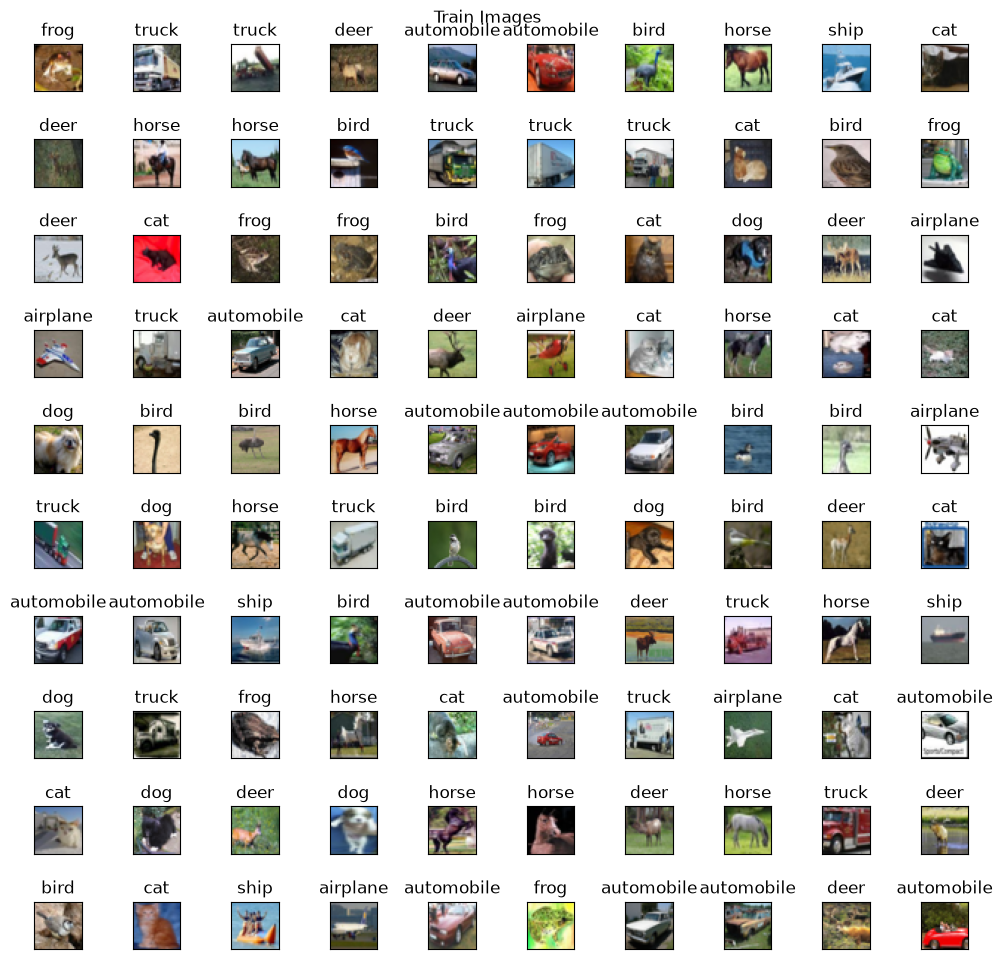

In [8]:
show_images(x_train, y_train, labels_text, "Train Images")

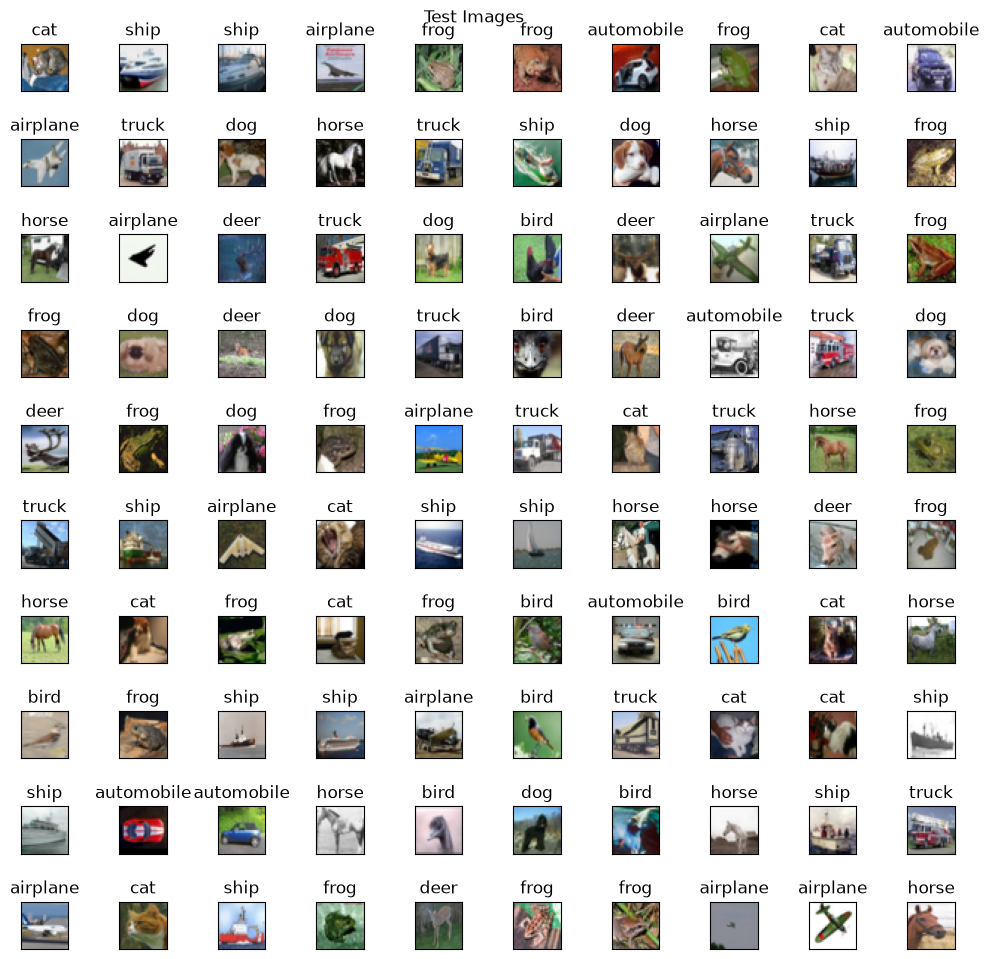

In [9]:
show_images(x_test, y_test, labels_text, "Test Images")

## CIFAR-10 Dataset Class

In [10]:
class CIFAR10DatasetLoader(Dataset):
    def __init__(self, x, y, transform: callable = None):
        assert(len(x) == len(y))
        self.x = x
        self.y = y
        self.transform = transform
    def __len__(self):
        return len(self.x)
    def __getitem__(self, i):
        x = self.x[i]
        y = self.y[i]
        if not self.transform is None:
            x = self.transform(x)
        return x, y

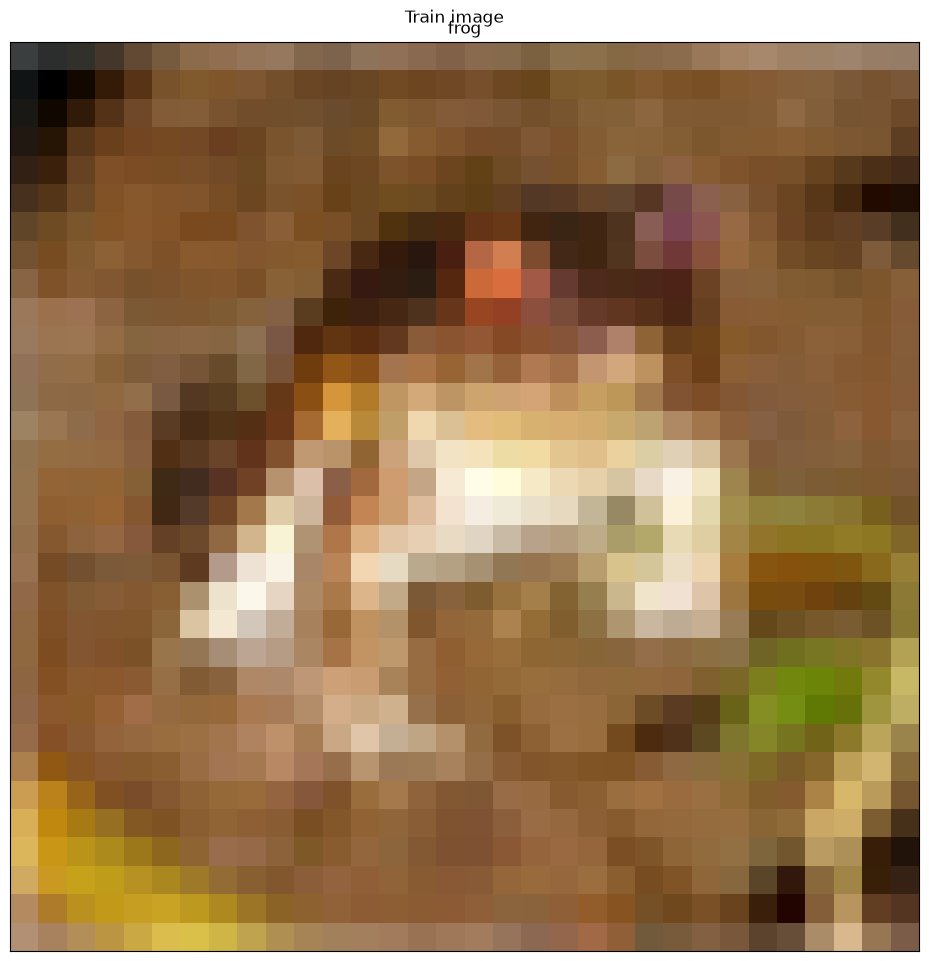

In [11]:
if True:
    tmp_loader = CIFAR10DatasetLoader(x_train, y_train)
    x, y = tmp_loader[0]
    show_images([x], [y], labels_text, "Train image")

## CNN

In [12]:
class ResNetBlock(nn.Module):
    def __init__(self, in_features, out_features, stride=1):
        super(ResNetBlock, self).__init__()
        self.conv1 = nn.Conv2d(in_features, out_features, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_features)
        self.conv2 = nn.Conv2d(out_features, out_features, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_features)
        if stride != 1:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_features, out_features, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_features)
            )
        else:
            self.shortcut = nn.Sequential()
    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        out += self.shortcut(x)
        out = F.relu(out)
        return out

class ResNet(nn.Module):
    def __init__(self, classes_num):
        super(ResNet, self).__init__()
        curr_features = 32
        n = 9 # ResNet{6*n+2}
        self.conv1 = nn.Conv2d(3, curr_features, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(curr_features)

        self.layer1 = self.add_resnet_layer(curr_features, 1, n)
        curr_features *= 1
        self.layer2 = self.add_resnet_layer(curr_features, 2, n)
        curr_features *= 2
        self.layer3 = self.add_resnet_layer(curr_features, 2, n)
        curr_features *= 2

        self.global_avg_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.flat = nn.Flatten()
        self.fc = nn.Linear(curr_features, classes_num)
    def add_resnet_layer(self, curr_features, stride, block_count):
        layers = [ResNetBlock(curr_features, curr_features*stride, stride=stride)]
        curr_features *= stride
        for _ in range(block_count-1):
            layers.append(ResNetBlock(curr_features, curr_features, stride=1))
        return nn.Sequential(*layers)
    def forward(self, x):
        x = F.relu(self.bn1(self.conv1(x)))
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        x = self.global_avg_pool(x)
        x = self.flat(x)
        x = self.fc(x)
        return x


In [13]:
print(ResNet(len(labels_text)))

ResNet(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (layer1): Sequential(
    (0): ResNetBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (shortcut): Sequential()
    )
    (1): ResNetBlock(
      (conv1): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): Ba

In [14]:
def torch_train(model, train_loader, optimizer, loss_func, epoch):
    model.train()
    tp = 0
    n = 0
    t_start = time.time()
    for i, (images, labels) in enumerate(train_loader):
        images = images.to(device)
        labels_gpu = labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_func(outputs, labels_gpu)
        loss.backward()
        optimizer.step()
        tp += (outputs.cpu().argmax(dim=1) == labels).sum()
        n += labels.size(0)
    elapsed = time.time() - t_start
    acc = tp / n
    print(f"TRAIN Epoch {epoch}, train acc: {acc}, train err: {1.0 - acc} train time: {elapsed}")
    return (acc, elapsed)

def torch_test(model, test_loader, epoch):
    model.eval()
    tp = 0
    n = 0
    with torch.no_grad():
        for i, (images, labels) in enumerate(test_loader):
            images = images.to(device)
            outputs = model(images).cpu()
            tp += (outputs.argmax(dim=1) == labels).sum()
            n += labels.size(0)
    acc = tp / n
    print(f"TEST Epoch {epoch}, test acc: {acc}, test err: {1.0 - acc}")
    return acc

In [15]:
class MyTransform(object):
    def __init__(self, mean, std, device):
        self.mean = np.float32(mean)
        self.std = np.float32(std)
        self.device = device
    def __call__(self, x: np.ndarray):
        x = (x.astype(np.float32) / 255.0)
        x = ((x - self.mean) / self.std).reshape((x.shape[2], x.shape[1], x.shape[0]))
        x = torch.from_numpy(x).to(self.device)
        return x

In [16]:
pytorch_res = {
    "train_acc": [],
    "train_time": [],
    "test_acc": []
}
if True:
    x_train_0_1 = x_train / 255.0
    transform = transforms.Compose([
        transforms.ToPILImage(),
        transforms.RandomCrop(32, padding=4),
        transforms.RandomHorizontalFlip(),
        lambda x: np.array(x),
        MyTransform(x_train_0_1.mean(axis=(0,1)), x_train_0_1.std(axis=(0,1)), device)
    ])
    transform_test = transforms.Compose([
        MyTransform(x_train_0_1.mean(axis=(0,1)), x_train_0_1.std(axis=(0,1)), device)
    ])
    dataset1 = CIFAR10DatasetLoader(x_train, y_train, transform=transform)
    dataset2 = CIFAR10DatasetLoader(x_test, y_test, transform=transform_test)
    batch_size = 128
    train_loader = DataLoader(dataset1, batch_size=batch_size, shuffle=True)
    test_loader = DataLoader(dataset2, batch_size=batch_size)
    model = ResNet(len(labels_text)).to(device)
    torch.backends.cudnn.benchmark = True
    optimizer = optim.SGD(model.parameters(), lr=0.1, weight_decay=0.0001, momentum=0.9)
    loss_func = nn.CrossEntropyLoss()
    epoch_count = 200
    scheduler = optim.lr_scheduler.MultiStepLR(optimizer, [int(epoch_count*0.5), int(epoch_count*0.75)], gamma=0.1)
    for epoch in range(epoch_count):
        train_acc, train_time = torch_train(model, train_loader, optimizer, loss_func, epoch)
        test_acc = torch_test(model, test_loader, epoch)
        pytorch_res["train_acc"].append(train_acc)
        pytorch_res["train_time"].append(train_time)
        pytorch_res["test_acc"].append(test_acc)
        scheduler.step()
    train_acc = np.array(pytorch_res["train_acc"])
    train_time = np.array(pytorch_res["train_time"])
    test_acc = np.array(pytorch_res["test_acc"])
    train_err = -train_acc + 1.0
    test_err = -test_acc + 1.0
    print(f"TRAIN avg train acc: {train_acc.mean()}, avg train err: {train_err.mean()}, avg train time: {train_time.mean()}, total train time: {train_time.sum()}")
    print(f"TEST avg test acc: {test_acc.mean()}, avg test_err {test_err.mean()}")
    # Save numpy
    pytorch_res["train_acc"] = train_acc
    pytorch_res["train_time"] = train_time
    pytorch_res["test_acc"] = test_acc

TRAIN Epoch 0, train acc: 0.16516000032424927, train err: 0.8348399996757507 train time: 21.192315816879272
TEST Epoch 0, test acc: 0.22679999470710754, test err: 0.7732000350952148
TRAIN Epoch 1, train acc: 0.22711999714374542, train err: 0.7728800177574158 train time: 20.760549306869507
TEST Epoch 1, test acc: 0.22470000386238098, test err: 0.7753000259399414
TRAIN Epoch 2, train acc: 0.2734200060367584, train err: 0.726580023765564 train time: 20.182544469833374
TEST Epoch 2, test acc: 0.3264000117778778, test err: 0.6735999584197998
TRAIN Epoch 3, train acc: 0.3238399922847748, train err: 0.6761599779129028 train time: 19.933756351470947
TEST Epoch 3, test acc: 0.34619998931884766, test err: 0.6538000106811523
TRAIN Epoch 4, train acc: 0.3667599856853485, train err: 0.6332399845123291 train time: 20.29249858856201
TEST Epoch 4, test acc: 0.3776000142097473, test err: 0.6223999857902527
TRAIN Epoch 5, train acc: 0.39052000641822815, train err: 0.6094800233840942 train time: 20.21604

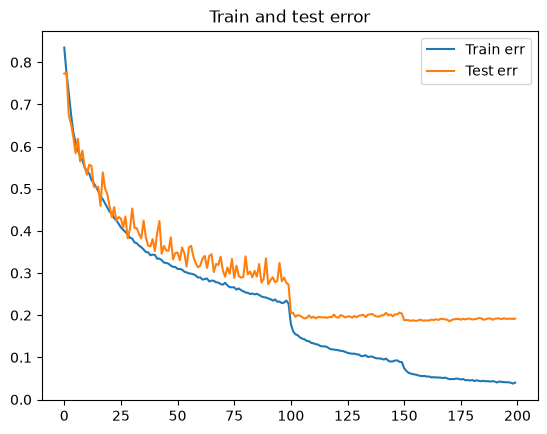

In [17]:
if True:
    x = np.arange(len(pytorch_res["train_acc"]))
    plt.plot(x, -pytorch_res["train_acc"] + 1.0, label="Train err")
    plt.plot(x, -pytorch_res["test_acc"] + 1.0, label="Test err")
    plt.title("Train and test error")
    plt.legend()
    plt.show()